# 07 - Composições mensais Sentinel-2 (10 m)

| | |
|---|---|
| **Tarefa do plano** | Dados óticos da Camada 2 (plano: Sentinel-2 L2A, 2017-2026) |
| **Variáveis (Parte I)** | #8 B2/B3/B4, #9 B8/B8A, #10 B11/B12, #11 máscara SCL |
| **Fonte** | Copernicus Sentinel-2 L2A via Earth Engine `COPERNICUS/S2_SR_HARMONIZED` |
| **Saída** | `data/raw/optical/sentinel2/<ano>/` |

Receita (`ete.datasets.sentinel2_builder`): máscara SCL (sem dados, saturado,
sombra de nuvem, nuvem média/alta, cirros), refletância convertida para 0-1,
mediana mensal, `n_obs`. Bandas: `blue, green, red, nir, nir_narrow, swir1, swir2,
n_obs`; as bandas de 20 m são reamostradas para 10 m.

O arquivo L2A no Earth Engine não começa na mesma data em todo o lado. Os meses
sem nenhuma cena L2A sobre Marracuene ficam registados como `absent` no manifesto
e não geram ficheiro - verificar o primeiro mês disponível no inventário abaixo.

Correr primeiro `00_setup_and_authentication` e `01_study_area_aoi`. Todos os
downloads podem ser retomados: os ficheiros que já existem são saltados, e cada
ficheiro fica registado em `data/metadata/download_manifest.csv`.

In [1]:
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config" / "config.yaml").exists())
sys.path.insert(0, str(ROOT / "src"))

import ee
import pandas as pd
import matplotlib.pyplot as plt

from ete import config, datasets, gee, series
from ete import grid as G

cfg = config.load_config()
gee.init(cfg)

aoi = G.load_aoi(cfg)                       # AOI das imagens (EPSG:4326)
region = gee.ee_geometry(aoi)
grid30 = G.load_grid(cfg)                   # grelha do projeto a 30 m (EPSG:32736)
grid10 = G.load_grid(cfg, 10)               # grelha a 10 m, encaixada na de 30 m
climate_bounds = tuple(G.load_aoi(cfg, "aoi_climate").total_bounds)   # O, S, E, N
MASK = gee.ee_geometry(G.imagery_mask(cfg))  # distrito + margem: fora daqui as imagens mensais ficam sem dados

*** Earth Engine *** Share your feedback by taking our Annual Developer Satisfaction Survey: https://google.qualtrics.com/jfe/form/SV_9oS0DRcPvElRMNw?source=python


## Parâmetros

**Formato dos ficheiros.** Os valores são guardados como inteiros (`DTYPE`), multiplicados
por `SCALE`, para ocupar menos disco e menos internet sem perda relevante de precisão.
O fator fica gravado dentro do GeoTIFF: ler sempre com `series.read_scaled(ficheiro)`,
que devolve os valores físicos. As bandas `n_obs` e `label_mode` não são multiplicadas.
Com `MASK`, os píxeis fora do distrito + margem ficam sem dados (-9999).

In [2]:
ds = cfg["datasets"]["sentinel2"]
DATASET, SOURCE_ID = "sentinel2", ds["id"]
BANDS = list(ds["bands"].values()) + ["n_obs"]
GRID, DTYPE, START = grid10, "int16", ds["start"]
SCALE = 10000                               # refletância guardada como inteiro (x10000), como no produto original
OUT_DIR = config.path(cfg, "sentinel2")
builder = datasets.sentinel2_builder(cfg, region)

## Teste com um mês

Correr sempre um mês primeiro e observá-lo antes de lançar o período completo.
`2023-02` está na época chuvosa, quando as nuvens e as cheias são mais prováveis.

In [3]:
TEST_MONTH = "2023-02"
test = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR,
                            start=f"{TEST_MONTH}-01", end=f"{TEST_MONTH}-28", dtype=DTYPE, scale=SCALE, mask=MASK)
test

sentinel2:   0%|          | 0/1 [00:00<?, ?it/s]

,period,status,file,n_images
0,2023-02,downloaded,sentinel2_marracuene_2023-02_10m.tif,22


('blue', 'green', 'red', 'nir', 'nir_narrow', 'swir1', 'swir2', 'n_obs') int16 EPSG:32736 (10.0, 10.0) (5412, 5244)
tamanho em disco: 129 MB
píxeis sem nenhuma observação limpa: 0.2%


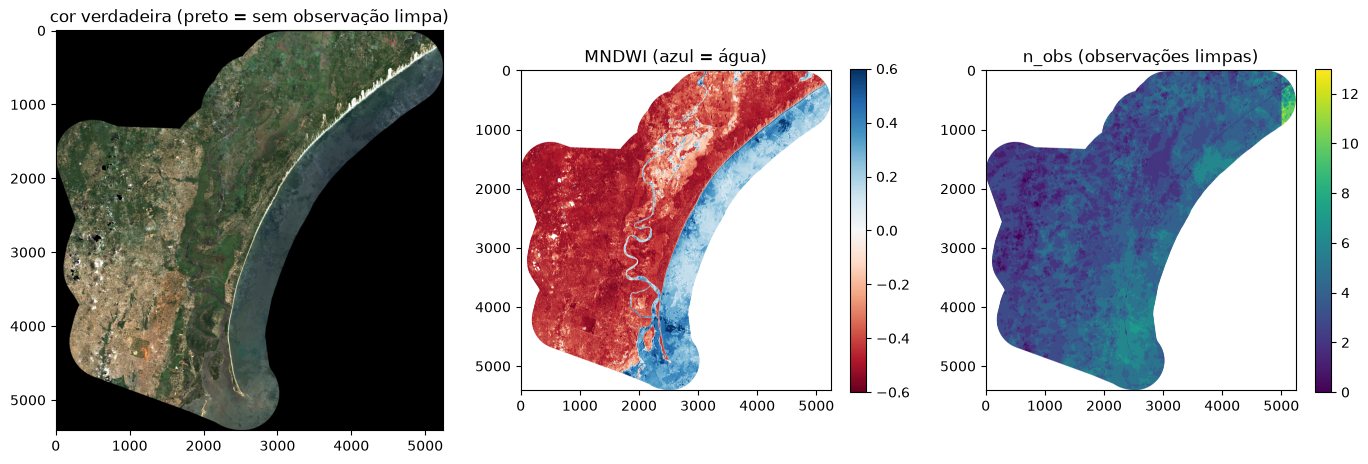

In [4]:
import numpy as np
import rasterio

test_file = next(OUT_DIR.rglob(f"*_{TEST_MONTH}_*.tif"))
with rasterio.open(test_file) as src:
    print(src.descriptions, src.dtypes[0], src.crs, src.res, src.shape)
print(f"tamanho em disco: {test_file.stat().st_size / 1e6:.0f} MB")
data, _ = series.read_scaled(test_file)      # valores físicos (refletância 0-1)
rgb = np.clip(np.ma.filled(data[[2, 1, 0]], 0).transpose(1, 2, 0) / 0.25, 0, 1)
green, swir1, n_obs = data[BANDS.index("green")], data[BANDS.index("swir1")], data[-1]
mndwi = (green - swir1) / (green + swir1)

fig, axes = plt.subplots(1, 3, figsize=(17, 7))
axes[0].imshow(rgb); axes[0].set_title("cor verdadeira (preto = sem observação limpa)")
im = axes[1].imshow(mndwi, cmap="RdBu", vmin=-0.6, vmax=0.6); axes[1].set_title("MNDWI (azul = água)"); plt.colorbar(im, ax=axes[1], shrink=0.6)
im = axes[2].imshow(n_obs, cmap="viridis"); axes[2].set_title("n_obs (observações limpas)"); plt.colorbar(im, ax=axes[2], shrink=0.6)
print(f"píxeis sem nenhuma observação limpa: {(n_obs == 0).mean():.1%}")

## Período completo

Demora bastante (horas para os datasets de 10 m). Pode ser interrompido e
retomado a qualquer momento; os meses já concluídos são saltados.

In [3]:
log = gee.download_monthly(cfg, DATASET, SOURCE_ID, builder, BANDS, GRID, OUT_DIR, start=START, dtype=DTYPE, scale=SCALE, mask=MASK)
log["status"].value_counts()

sentinel2:   0%|          | 0/117 [00:00<?, ?it/s]

status
exists        96
downloaded    20
absent         1
Name: count, dtype: int64

## Inventário

In [4]:
inv = series.monthly_inventory(OUT_DIR)
expected = [m.strftime("%Y-%m") for m in gee.month_starts(START, config.period_end(cfg))]
missing = sorted(set(expected) - set(inv["period"]))
print(f"{len(inv)} ficheiros, {inv['size_mb'].sum() / 1e3:.2f} GB em disco")
print(f"{len(missing)} de {len(expected)} meses sem ficheiro (ausentes na fonte ou com falha):")
print(missing)

116 ficheiros, 16.53 GB em disco
1 de 117 meses sem ficheiro (ausentes na fonte ou com falha):
['2018-08']
